> **Estado de validación:** Entrenamiento real de 20 épocas con Roboflow; evaluación de test y pesos guardados.

In [1]:
%matplotlib inline
# Dependencias instaladas desde requirements.txt.
import ultralytics

In [2]:
from roboflow import Roboflow
from dotenv import load_dotenv
import os
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# apikeys.env NO debe subirse a git ni compartirse: agrega la carpeta/archivo a .gitignore.
# Crea tu propio apikeys.env junto al notebook con una linea:
#   ROBOFLOW_API_KEY=tu_api_key_aqui
load_dotenv("apikeys.env")

api_key = os.getenv("ROBOFLOW_API_KEY")
if not api_key:
    raise RuntimeError(
        "No se encontro ROBOFLOW_API_KEY. Crea un archivo apikeys.env junto a este "
        "notebook con la linea: ROBOFLOW_API_KEY=tu_api_key_aqui"
    )
from pathlib import Path
import torch, json, shutil
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
print("Dispositivo:", DEVICE)


Dispositivo: mps


In [3]:
# Datos del proyecto y versión exactos indicados por el profesor.
from types import SimpleNamespace
import contextlib, io
DATASET_DIR = Path("datasets/sitesafety")
if (DATASET_DIR / "data.yaml").exists():
    dataset = SimpleNamespace(location=str(DATASET_DIR.resolve()))
else:
    capture = io.StringIO()
    try:
        # Evita que enlaces de descarga autenticados aparezcan en las salidas.
        with contextlib.redirect_stdout(capture), contextlib.redirect_stderr(capture):
            rf = Roboflow(api_key=api_key)
            project = rf.workspace("semilleroml").project("sitesafety-pbakq")
            dataset = project.version(1).download("yolo26", location=str(DATASET_DIR.resolve()))
    except Exception:
        raise RuntimeError("No se pudo descargar el dataset; comprueba conexión, clave y acceso al proyecto.") from None
print("Dataset local:", DATASET_DIR)
print("Imágenes por partición:", {s:len(list((DATASET_DIR/s/"images").glob("*"))) for s in ["train","valid","test"]})


Dataset local: datasets/sitesafety
Imágenes por partición: {'train': 4, 'valid': 2, 'test': 3}


In [4]:
model = YOLO("yolo26n.pt")
# Se conservan 20 épocas y todas las imágenes; batch=8 y workers=0 permiten
# entrenar en este Mac. Seed fijo para reproducibilidad; MPS puede variar levemente.
results = model.train(data=str((DATASET_DIR/"data.yaml").resolve()), epochs=20,
    imgsz=640, batch=8, workers=0, device=DEVICE, seed=42,
    project="runs/talleres", name="sitesafety", exist_ok=True)


Ultralytics 8.4.174 🚀 Python-3.11.15 torch-2.14.1 MPS (Apple M4)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/datasets/sitesafety/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=sitesafety, nbs=64, nms=None, opset=None, optimize=Fal

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.5it/s 0.7s

                   all          2          2    0.00597          1      0.745      0.447


                helmet          2          2    0.00597          1      0.745      0.447


Speed: 5.9ms preprocess, 310.1ms inference, 0.0ms loss, 6.7ms postprocess per image


Results saved to /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/runs/detect/runs/talleres/sitesafety


In [5]:
import glob

# Ruta portable: tomamos la primera imagen del set de test que se descargo con Roboflow,
# en vez de una ruta absoluta especifica de una maquina/Studio.
test_images = sorted(glob.glob(f"{dataset.location}/test/images/*.jpg"))
assert test_images, f"No se encontraron imagenes de test en {dataset.location}/test/images"
image_path = test_images[0]
print(f"Usando imagen de prueba: {image_path}")

resultados = model(image_path, conf=0.001, iou=0.7)

Usando imagen de prueba: /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/datasets/sitesafety/test/images/00596_jpg.rf.069990c2f14e9a321e05f3d069869555.jpg



image 1/1 /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/datasets/sitesafety/test/images/00596_jpg.rf.069990c2f14e9a321e05f3d069869555.jpg: 640x640 209 helmets, 91 vests, 28.0ms


Speed: 0.9ms preprocess, 28.0ms inference, 2.9ms postprocess per image at shape (1, 3, 640, 640)


In [6]:
r = resultados[0] # r es un objeto de tipo 'ultralytics.yolo.engine.results.Results' que contiene toda la informacion de la inferencia

print("=== Informacion general ===")
print(f"Imagen original: {r.path}")
print(f"Tamano procesado: {r.orig_shape}")
print(f"Objetos detectados: {len(r.boxes)}")


print("\n=== Detecciones ===")
for i, box in enumerate(r.boxes):
    clase_id  = int(box.cls[0])
    clase_nom = model.names[clase_id]
    confianza = float(box.conf[0])
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    
    print(f"  [{i+1}] {clase_nom:15s} | confianza: {confianza:.2f} | bbox: ({x1:.0f},{y1:.0f}) → ({x2:.0f},{y2:.0f})")

=== Informacion general ===
Imagen original: /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/datasets/sitesafety/test/images/00596_jpg.rf.069990c2f14e9a321e05f3d069869555.jpg
Tamano procesado: (640, 640)
Objetos detectados: 300

=== Detecciones ===
  [1] helmet          | confianza: 0.01 | bbox: (198,109) → (324,242)
  [2] vest            | confianza: 0.01 | bbox: (91,370) → (215,640)
  [3] vest            | confianza: 0.01 | bbox: (343,340) → (494,639)
  [4] vest            | confianza: 0.01 | bbox: (344,423) → (457,640)
  [5] vest            | confianza: 0.01 | bbox: (437,422) → (640,640)
  [6] helmet          | confianza: 0.01 | bbox: (91,453) → (215,640)
  [7] helmet          | confianza: 0.01 | bbox: (185,109) → (325,315)
  [8] helmet          | confianza: 0.01 | bbox: (90,348) → (215,640)
  [9] helmet          | confianza: 0.01 | bbox: (331,112) → (502,247)
  [10] vest            | confianza: 0.01 | bbox: (199,344) → (313,553)
  [11] vest 

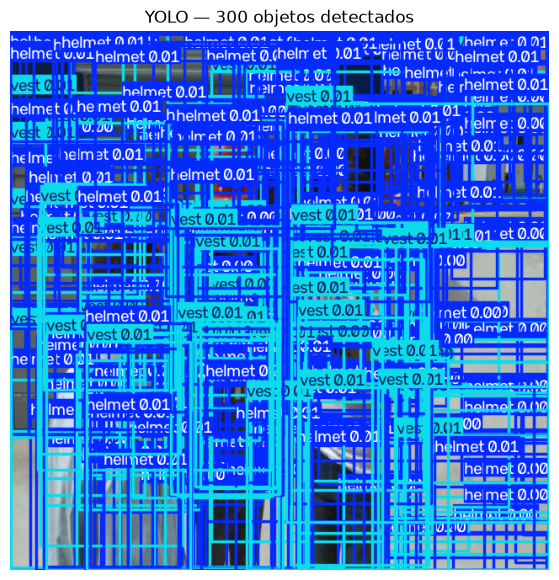

In [7]:
# r.plot() retorna la imagen anotada como array NumPy (BGR → convertir a RGB para matplotlib)
imagen_anotada = r.plot()
imagen_anotada_rgb = imagen_anotada[:, :, ::-1]  # BGR a RGB

plt.figure(figsize=(12, 7))
plt.imshow(imagen_anotada_rgb)
plt.title(f"YOLO — {len(r.boxes)} objetos detectados")
plt.axis("off")
plt.show()

Ultralytics 8.4.174 🚀 Python-3.11.15 torch-2.14.1 MPS (Apple M4)


YOLO26n summary (fused): 120 layers, 2,375,226 parameters, 0 gradients, 5.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 519.3±645.6 MB/s, size: 49.1 KB)


val: Scanning /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/datasets/sitesafety/test/labels... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3 1.4Kit/s 0.0s

val: New cache created: /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/datasets/sitesafety/test/labels.cache


...

                helmet          3          3    0.00665          1      0.913      0.359


                  vest          2          2    0.00445          1     0.0622     0.0184


Speed: 2.1ms preprocess, 62.4ms inference, 0.0ms loss, 6.4ms postprocess per image


Results saved to /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/runs/detect/runs/talleres/sitesafety_test


{
  "project": "semilleroml/sitesafety-pbakq",
  "version": 1,
  "epochs": 20,
  "device": "mps",
  "classes": {
    "0": "helmet",
    "1": "vest"
  },
  "test_map50": 0.4873437500000001,
  "test_map50_95": 0.1888397743395377,
  "test_precision": 0.005553113842537494,
  "test_recall": 1.0,
  "test_images": 3
}


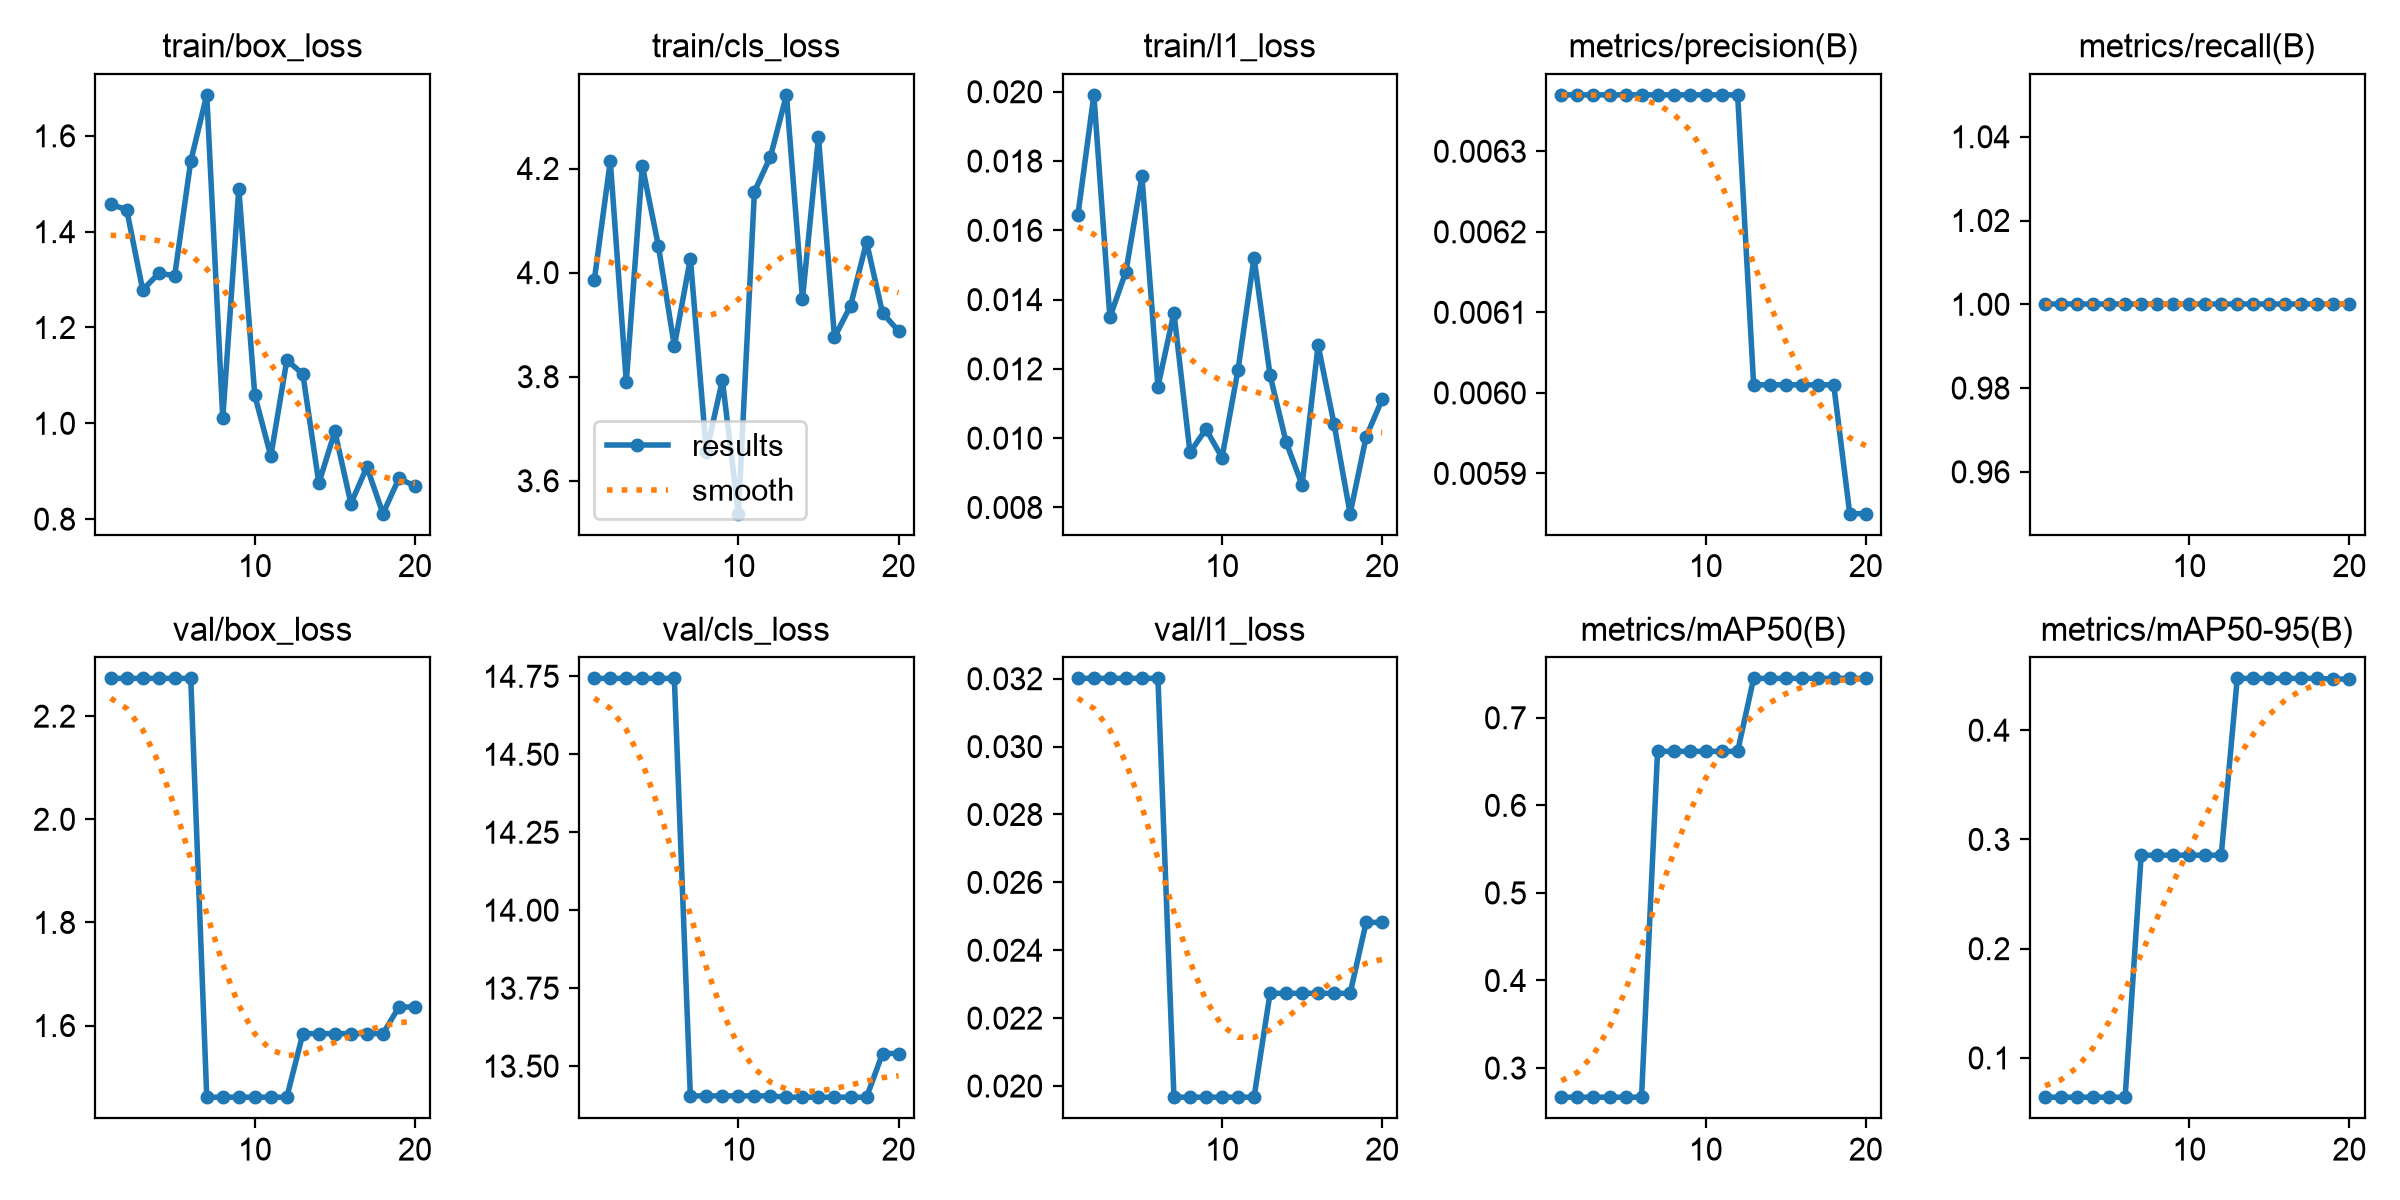

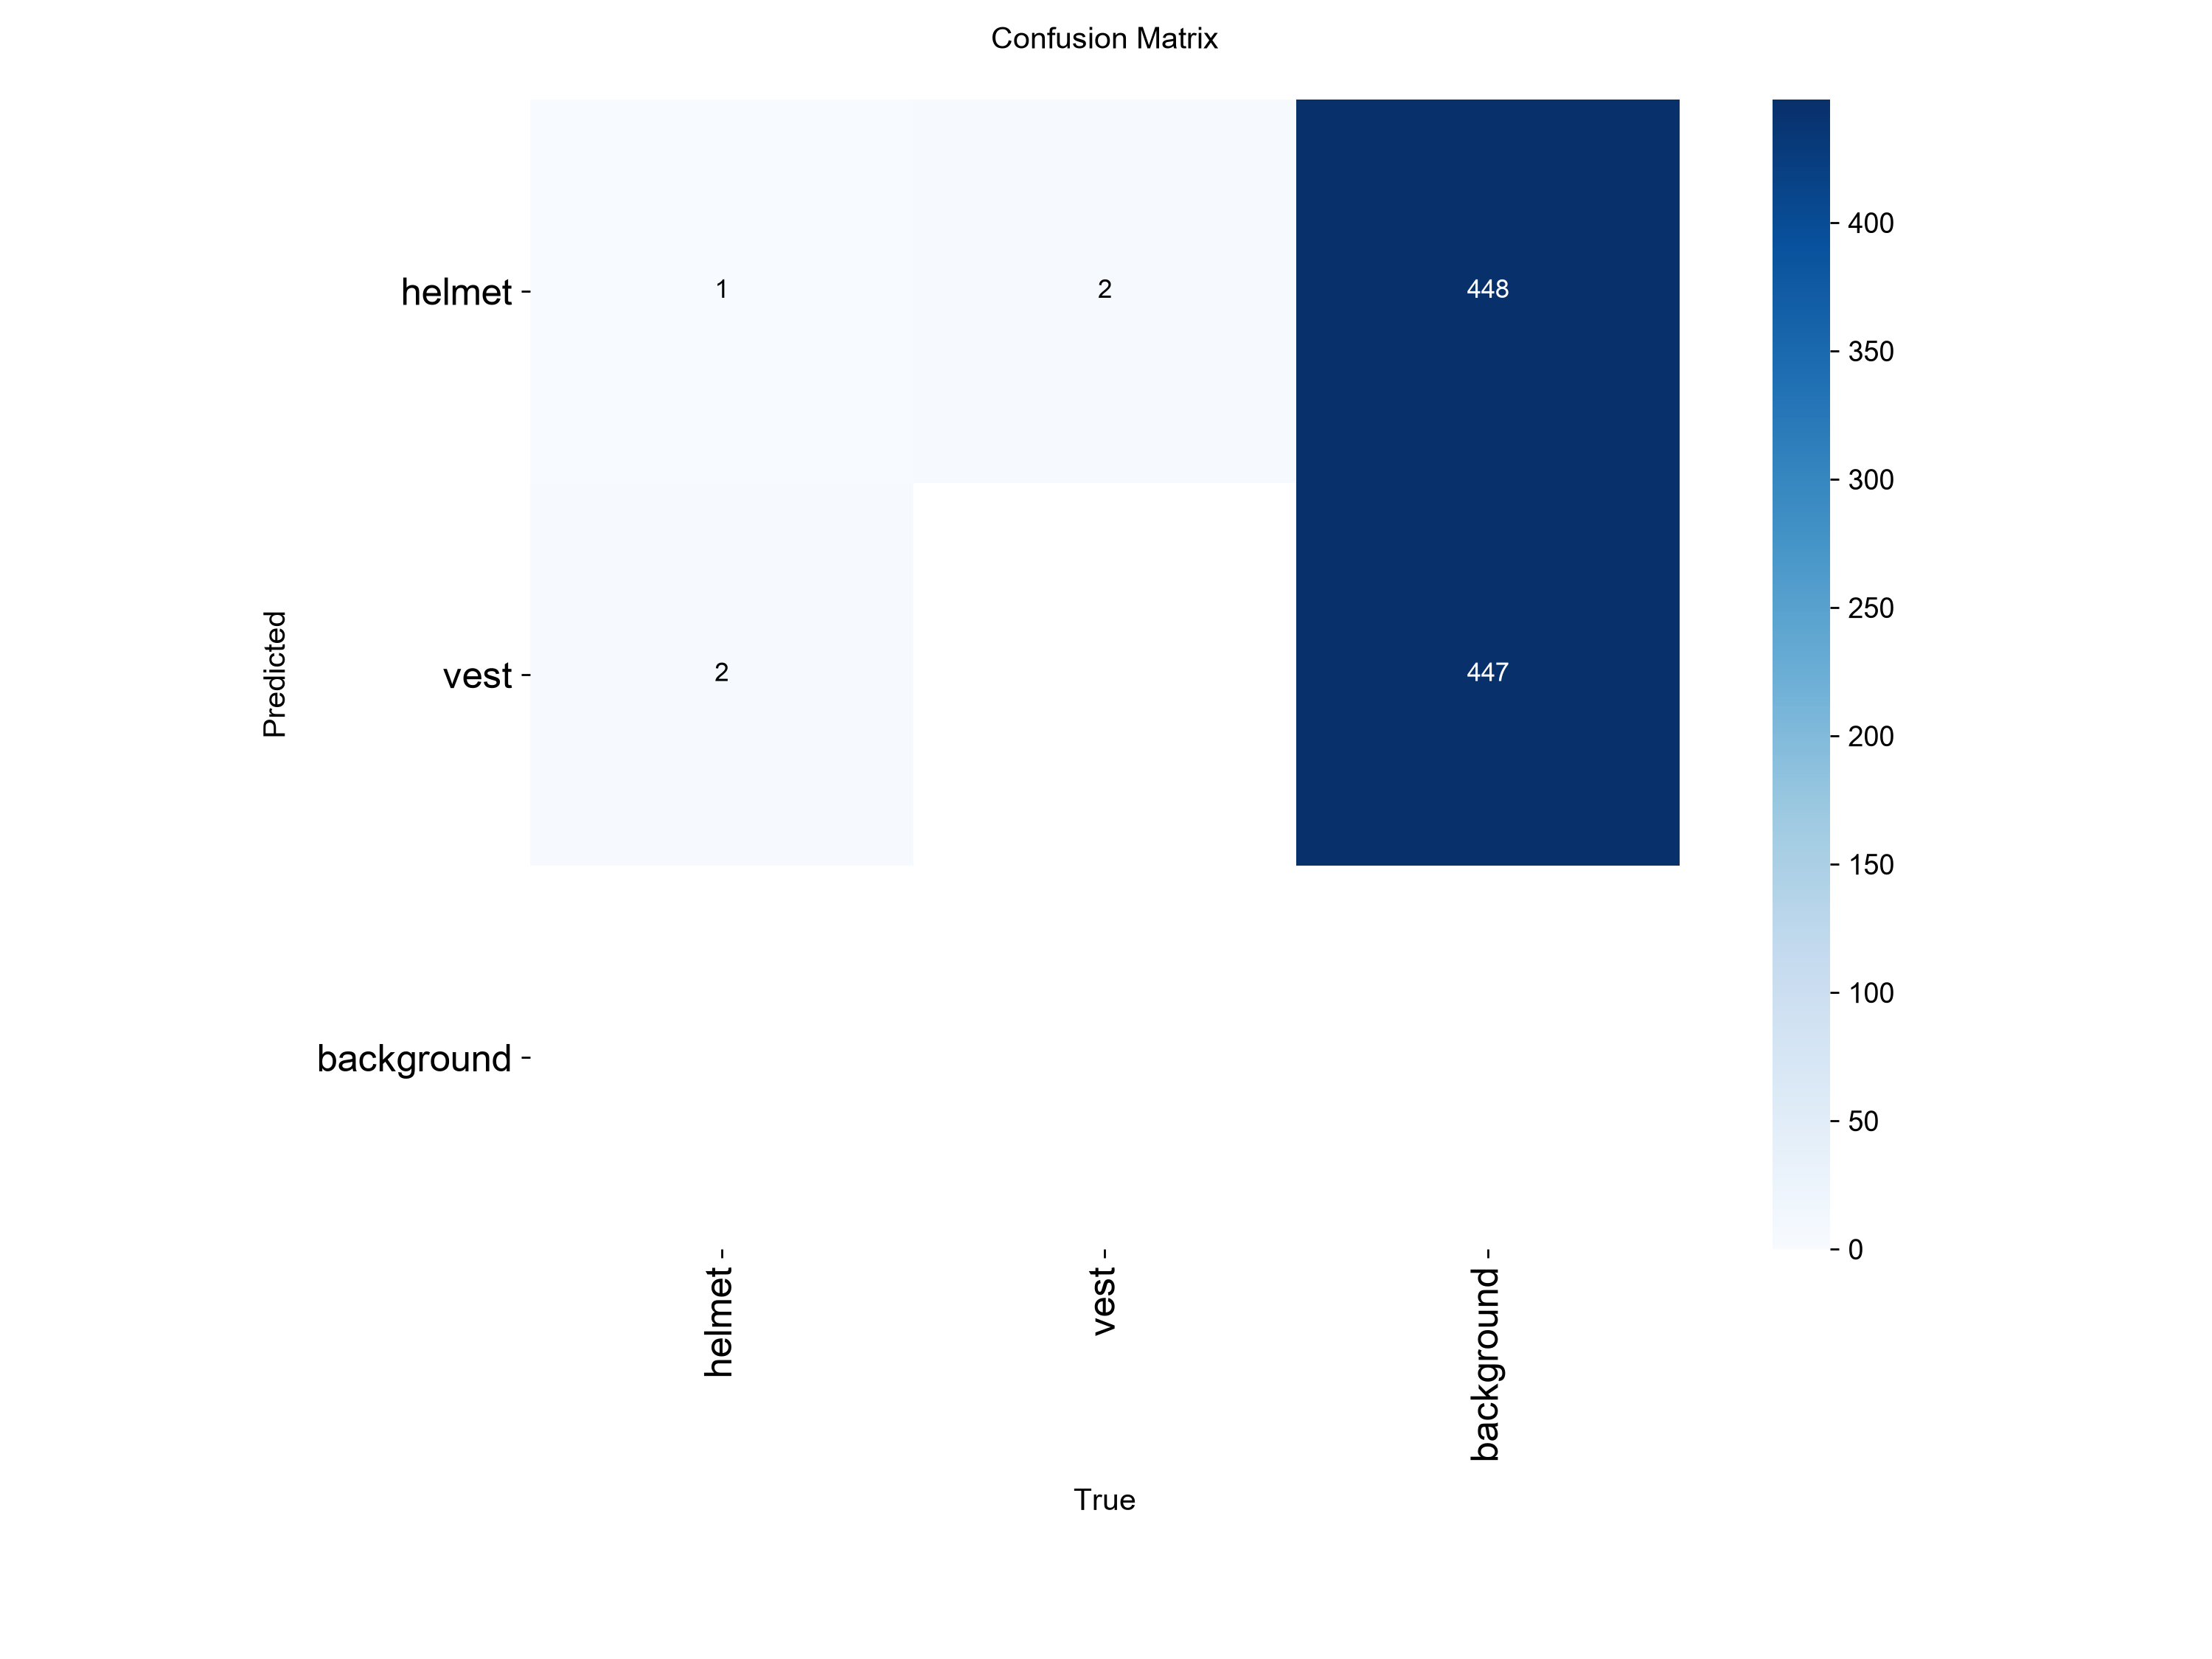

In [8]:
# Evaluación de prueba después de completar el entrenamiento.
# YOLO carga los mejores pesos elegidos por validación al terminar train().
test_metrics = model.val(data=str((DATASET_DIR/"data.yaml").resolve()), split="test",
    imgsz=640, batch=8, workers=0, device=DEVICE, plots=True,
    project="runs/talleres", name="sitesafety_test", exist_ok=True)
report = {"project":"semilleroml/sitesafety-pbakq", "version":1, "epochs":20,
    "device":DEVICE, "classes":model.names,
    "test_map50":float(test_metrics.box.map50),
    "test_map50_95":float(test_metrics.box.map),
    "test_precision":float(test_metrics.box.mp), "test_recall":float(test_metrics.box.mr),
    "test_images":len(list((DATASET_DIR/"test"/"images").glob("*")))}
Path("reports").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
Path("reports/sitesafety_metrics.json").write_text(json.dumps(report,indent=2))
shutil.copy2(model.trainer.best, "models/sitesafety_best.pt")
shutil.copy2(model.trainer.save_dir/"results.csv", "reports/sitesafety_training.csv")
print(json.dumps(report,indent=2))
from IPython.display import display, Image as DisplayImage
for filename in ["results.png"]:
    img = model.trainer.save_dir/filename
    if img.exists(): display(DisplayImage(filename=str(img)))
confusion = Path(test_metrics.save_dir)/"confusion_matrix.png"
if confusion.exists(): display(DisplayImage(filename=str(confusion)))


## Interpretación y procedencia

Se utilizaron los datos públicos del proyecto del profesor, no datos recolectados personalmente. Las métricas de la última celda pertenecen al entrenamiento local de 20 épocas y a su evaluación en test; no son las métricas publicadas por Roboflow. `mAP50` evalúa AP con IoU=0,50; `mAP50-95` promedia umbrales más exigentes. Una detección correcta debe acertar tanto clase como localización. La confianza de una sola imagen no reemplaza evaluar el conjunto de prueba.


### Interpretación del entrenamiento

El conjunto contiene solamente 4 imágenes de entrenamiento, 2 de validación y 3 de prueba. Tras 20 épocas, mAP50 de test = 0,4873 y mAP50–95 = 0,1888. La precisión reportada es 0,0056 y el recall 1,0: hay muchos falsos positivos en el punto de operación seleccionado. Estos tres casos no permiten concluir que el detector sea fiable. Se necesitan más imágenes diversas y anotadas, especialmente para equilibrar las clases, antes de usarlo en seguridad industrial.

Este ejemplo utiliza el proyecto público del docente; no se presenta como un dataset recolectado por la estudiante.

La matriz de confusión confirma confusiones entre cascos y chalecos en estas imágenes. Sus valores dependen del umbral usado para construir la matriz; no son el mismo punto de operación que el resumen de la curva precisión–recall.